<a href="https://colab.research.google.com/github/EstherMan05/ds2002-fa26/blob/main/notebooks/06-midterm-walmart/2026-10-30%20%E2%80%94%20Midterm%20Progress%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [1]:
# Setup: load and clean our team's data (same steps as team_notebook.ipynb sections 1-2.2, condensed)
import pandas as pd, numpy as np, matplotlib.pyplot as plt, matplotlib.dates as mdates
BASE = ('https://raw.githubusercontent.com/aymanr8-dot/DS-2002-Walmart-Hurricane-Project_Data-Demons-/main/data/')
raw = pd.read_csv(BASE + 'walmart_transactions.csv', dtype=str)
stores = pd.read_csv(BASE + 'store_locations.csv', dtype=str)

def clean_store_id(s):
    s = s.astype(str).str.strip().str.upper().str.replace(r'[^A-Z0-9]', '', regex=True)
    return s.str.replace(r'^([A-Z]{2})(\d+)$', r'\1-\2', regex=True)

sales = raw.drop_duplicates().copy()
sales['store_id'] = clean_store_id(sales['store_id'])
sales['quantity'] = pd.to_numeric(sales['quantity']).astype(int)
ts = sales['timestamp'].str.strip()
parsed = pd.Series(pd.NaT, index=sales.index, dtype='datetime64[ns]')
for fmt in ['%Y-%m-%d %H:%M:%S', '%Y-%m-%dT%H:%M:%S', '%m/%d/%Y %H:%M', '%m-%d-%Y %H:%M:%S', '%d-%b-%Y %H:%M']:
    parsed = parsed.fillna(pd.to_datetime(ts, format=fmt, errors='coerce'))
sales['date'] = parsed.dt.normalize()

# SKU -> product: link SKUs that cashiers sold under the same product name (union-find), then name each group
CANONICAL = {'PT-12': 'Pop-Tarts Strawberry', 'WTR-24': 'Bottled Water 24-Pack', 'BATT-100': 'AA Batteries 4-Pack',
             'FLASH-01': 'LED Flashlight', 'BEER-24': 'Light Beer 24-Pack', 'BG-MONO': 'Monopoly Board Game',
             'CARDS-01': 'Playing Cards', 'STREAM-01': 'Roku Streaming Stick', 'SOUP-CAN': 'Canned Soup',
             'BREAD-WH': 'White Bread', 'PB-16': 'Peanut Butter 16oz', 'CNDL-EM': 'Emergency Candles',
             'FAID-01': 'First Aid Kit', 'CHRG-PORT': 'Portable Phone Charger', 'CHIPS-VP': 'Chips Variety Pack',
             'PTOWEL-6': 'Paper Towels 6-Roll', 'TP-12': 'Toilet Paper 12-Roll', 'DIAP-S3': 'Diapers Size 3',
             'BFORM-01': 'Infant Formula', 'TARP-HD': 'Heavy Duty Tarp'}
sales['sku'] = sales['sku'].str.strip().str.upper()
pairs = pd.DataFrame({'sku': sales['sku'],
                      'name': sales['product_name'].str.strip().str.lower().str.replace(r'\s+', ' ', regex=True)}).drop_duplicates()
parent = {}
def find(x):
    parent.setdefault(x, x)
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
for s, n in pairs.itertuples(index=False):
    a, b = find('S:' + s), find('N:' + n)
    if a != b: parent[a] = b
groups = {}
for s in sorted(set(pairs['sku'])):
    groups.setdefault(find('S:' + s), []).append(s)
SKU_MAP = {}
for members in groups.values():
    keys = [s for s in members if s in CANONICAL]
    assert len(keys) == 1, members
    SKU_MAP.update({s: CANONICAL[keys[0]] for s in members})
sales['product'] = sales['sku'].map(SKU_MAP)
assert sales['product'].notna().all()

# Demand view: returns excluded, rows with no timestamp left out of anything by date
dated = sales[(sales['quantity'] > 0) & sales['date'].notna()]
BASELINE_START, BASELINE_END = pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-14')
SURGE_START, SURGE_END = pd.Timestamp('2024-09-16'), pd.Timestamp('2024-09-26')
LANDFALL = pd.Timestamp('2024-09-26')   # storm arrival = peak store-average gust in Open-Meteo data (team notebook 3.2)
daily = dated.groupby(['date', 'product'])['quantity'].sum().unstack().fillna(0)
print(f'{len(raw):,} raw rows -> {len(sales):,} clean | {sales["sku"].nunique()} SKUs -> {sales["product"].nunique()} products')
print('dates:', daily.index.min().date(), 'to', daily.index.max().date())

# ---- Q1 numbers ----
daily_units = dated.groupby('date')['quantity'].sum()
base = daily_units[BASELINE_START:BASELINE_END]
threshold = base.mean() + 3 * base.std()
surge_days = daily_units['2024-09-15':LANDFALL][lambda s: s > threshold].index
assert (surge_days.min(), surge_days.max()) == (SURGE_START, SURGE_END), 'surge window moved'
surge_avg = daily_units[SURGE_START:SURGE_END].mean()
Q1_MULTIPLE = surge_avg / base.mean()
pt_daily = daily['Pop-Tarts Strawberry']
pt_multiple = pt_daily[SURGE_START:SURGE_END].mean() / pt_daily[BASELINE_START:BASELINE_END].mean()
print(f'Baseline window: {BASELINE_START:%b %d}-{BASELINE_END:%b %d} (14 days) | avg {base.mean():,.0f} units/day | CV {base.std()/base.mean():.1%}')
print(f'Surge window:    {SURGE_START:%b %d}-{SURGE_END:%b %d} ({len(surge_days)} days, every day > mean + 3 SD = {threshold:,.0f}) | avg {surge_avg:,.0f} units/day')
print(f'Multiple (all products): {Q1_MULTIPLE:.2f}x  (+{100*(Q1_MULTIPLE-1):.0f}%)')
print(f'Top product, Pop-Tarts Strawberry: {pt_multiple:.2f}x over the window, '
      f'{pt_daily["2024-09-24":"2024-09-25"].mean()/pt_daily[BASELINE_START:BASELINE_END].mean():.1f}x at the Sept 24-25 peak')
print(f'Rows with no timestamp left out of by-date work: {(sales["date"].isna() & (sales["quantity"] > 0)).sum()}')


25,562 raw rows -> 25,532 clean | 45 SKUs -> 20 products
dates: 2024-09-01 to 2024-09-30
Baseline window: Sep 01-Sep 14 (14 days) | avg 1,109 units/day | CV 2.9%
Surge window:    Sep 16-Sep 26 (11 days, every day > mean + 3 SD = 1,206) | avg 2,347 units/day
Multiple (all products): 2.12x  (+112%)
Top product, Pop-Tarts Strawberry: 4.21x over the window, 8.4x at the Sept 24-25 peak
Rows with no timestamp left out of by-date work: 881


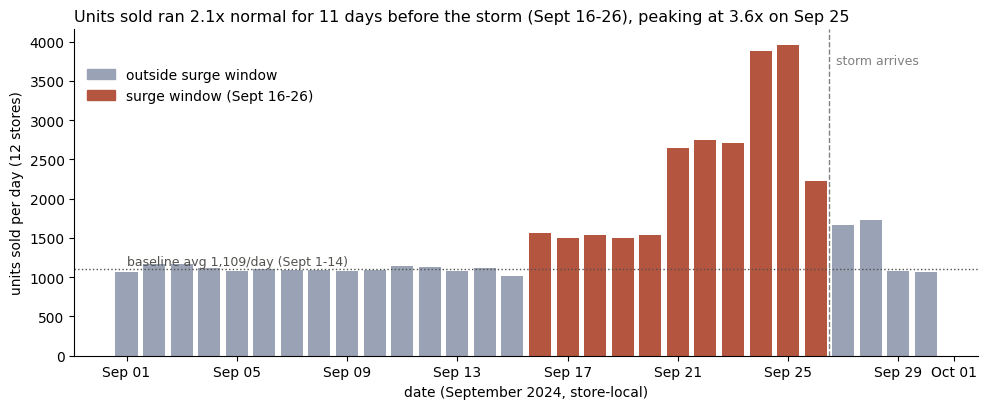

In [2]:
# ---- Q1 chart ----
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(daily_units.index, daily_units.values, width=0.8,
       color=['#b4553f' if SURGE_START <= d <= SURGE_END else '#9aa3b5' for d in daily_units.index])
ax.axhline(base.mean(), color='#52514e', lw=1, ls=':')
ax.text(pd.Timestamp('2024-09-01'), base.mean() * 1.04, f'baseline avg {base.mean():,.0f}/day (Sept 1-14)', fontsize=9, color='#52514e')
ax.axvline(LANDFALL + pd.Timedelta(hours=12), color='gray', ls='--', lw=1)
ax.text(LANDFALL + pd.Timedelta(hours=18), daily_units.max() * 0.97, 'storm arrives', fontsize=9, color='gray', va='top')
ax.set_title(f'Units sold ran {Q1_MULTIPLE:.1f}x normal for 11 days before the storm (Sept 16-26), peaking at '
             f'{daily_units.max()/base.mean():.1f}x on {daily_units.idxmax():%b %d}', loc='left', fontsize=11.5)
ax.set_ylabel('units sold per day (12 stores)')
ax.set_xlabel('date (September 2024, store-local)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color='#9aa3b5'), plt.Rectangle((0, 0), 1, 1, color='#b4553f')],
          labels=['outside surge window', 'surge window (Sept 16-26)'], frameon=False, loc='upper left', bbox_to_anchor=(0, 0.92))
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout(); plt.show()


**Q1 answer, in one sentence a manager could read:** Against a flat Sept 1–14 baseline (1,109 units/day across 12 stores), sales ran **2.1x normal** (2,347 units/day) for the 11 days from Sept 16 to the storm's arrival on Sept 26 and peaked at 3.6x on Sept 25; Strawberry Pop-Tarts moved most, at 4.2x over the window and 8.4x at the Sept 24–25 peak.

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

Distinct SKUs (after trimming/upper-casing): 45 -> canonical products: 20
Largest family: Pop-Tarts Strawberry = 4 SKUs: ['POPTART-STRAW', 'PT-12', 'PT_STRAWBERRY', 'SKU#459812']
Family sizes: {4: 1, 3: 3, 2: 16} (SKUs per product: count of products)
ASSERT PASSED: unit total 49,343 is identical by SKU and by product; row count unchanged (25,532)

Before (by SKU): #1 is WTR_24PK (Bottled Water 24-Pack) at 92/day; Pop-Tarts SKUs rank [4, 5, 5, 8]
After (by product): #1 is Pop-Tarts Strawberry at 312/day, 3.8x its largest single SKU


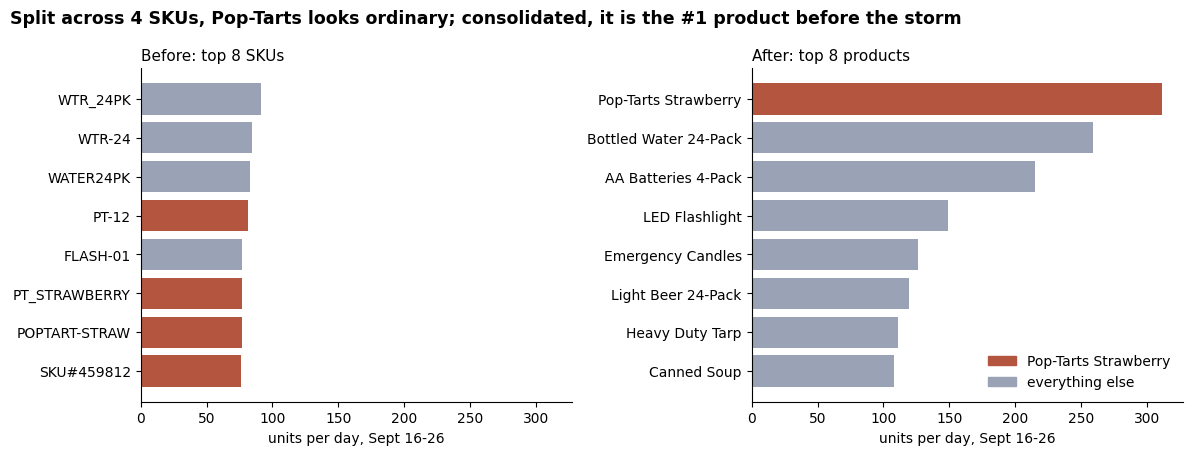

In [3]:
# ---- Q2: SKU consolidation ----
n_skus, n_products = sales['sku'].nunique(), sales['product'].nunique()
family = sales.groupby('product')['sku'].nunique().sort_values(ascending=False)
print(f'Distinct SKUs (after trimming/upper-casing): {n_skus} -> canonical products: {n_products}')
print(f'Largest family: {family.index[0]} = {family.iloc[0]} SKUs: {sorted(sales.loc[sales["product"] == family.index[0], "sku"].unique())}')
print('Family sizes:', family.value_counts().sort_index(ascending=False).to_dict(), '(SKUs per product: count of products)')

# Consolidation only relabels rows, so unit totals must be identical at every level
assert sales.groupby('sku')['quantity'].sum().sum() == sales.groupby('product')['quantity'].sum().sum() == sales['quantity'].sum()
assert len(sales) == len(raw.drop_duplicates()), 'consolidation changed the row count'
print(f'ASSERT PASSED: unit total {sales["quantity"].sum():,} is identical by SKU and by product; row count unchanged ({len(sales):,})')

# Before vs after, surge window (units/day)
n_days = (SURGE_END - SURGE_START).days + 1
surge = dated[dated['date'].between(SURGE_START, SURGE_END)]
by_sku = (surge.groupby('sku')['quantity'].sum() / n_days).sort_values(ascending=False)
by_product = (surge.groupby('product')['quantity'].sum() / n_days).sort_values(ascending=False)
pt = 'Pop-Tarts Strawberry'
pt_sku_ranks = by_sku.rank(ascending=False, method='min')[[s for s in by_sku.index if SKU_MAP[s] == pt]]
print(f'\nBefore (by SKU): #1 is {by_sku.index[0]} ({SKU_MAP[by_sku.index[0]]}) at {by_sku.iloc[0]:.0f}/day; '
      f'Pop-Tarts SKUs rank {sorted(pt_sku_ranks.astype(int).tolist())}')
print(f'After (by product): #1 is {by_product.index[0]} at {by_product.iloc[0]:.0f}/day, '
      f'{by_product.iloc[0] / by_sku[pt_sku_ranks.index].max():.1f}x its largest single SKU')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True)
for ax, d, title, lab in [(axes[0], by_sku.head(8).iloc[::-1], 'Before: top 8 SKUs', lambda s: s),
                          (axes[1], by_product.head(8).iloc[::-1], 'After: top 8 products', lambda s: s)]:
    is_pt = [(SKU_MAP.get(i, i) == pt) for i in d.index]
    ax.barh(d.index, d.values, color=['#b4553f' if x else '#9aa3b5' for x in is_pt])
    ax.set_title(title, fontsize=11, loc='left'); ax.set_xlabel('units per day, Sept 16-26')
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
axes[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color='#b4553f'), plt.Rectangle((0, 0), 1, 1, color='#9aa3b5')],
               labels=['Pop-Tarts Strawberry', 'everything else'], frameon=False, loc='lower right')
fig.suptitle('Split across 4 SKUs, Pop-Tarts looks ordinary; consolidated, it is the #1 product before the storm',
             x=0.01, ha='left', fontsize=12.5, fontweight='bold')
plt.tight_layout(); plt.show()


**Q2 answer:** We started with **45 distinct SKUs** and consolidated them to **20 canonical products**; the largest family is Strawberry Pop-Tarts (4 SKUs: PT-12, SKU#459812, POPTART-STRAW, PT_STRAWBERRY), and the assertion confirms unit totals (49,343) are identical before and after. Consolidation changes the rank, not the lift: by SKU, water tops the surge list (~92/day) and the four Pop-Tarts lines sit at ranks 4, 5, 5 and 8, but as one product Pop-Tarts is **#1 at 312 units/day, 3.8x its largest single SKU**.

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

Weather source: live (live: open-meteo archive API), 9,216 hourly rows, 12 stores
Join rows: 360 sales store-days before -> 360 after | null weather values: 0 | units preserved: 47,897 = 47,897

Same-day statewide r over 30 days: {'max_gust_mph': 0.22, 'min_pressure_hpa': -0.24, 'precip_in': -0.32}
Best lead (within-store, averaged over 12 stores): k = +2 days, gust r = +0.71, pressure r = -0.76
Peak sales day Sep 25 vs peak gust day Sep 26


,max_gust_mph,min_pressure_hpa,precip_in
k (weather k days after sales),,,
-3,-0.22,0.01,-0.36
-2,-0.13,-0.09,-0.35
-1,0.00,-0.15,-0.34
0,0.18,-0.25,-0.19
1,0.50,-0.57,-0.01
2,0.71,-0.76,0.02
3,0.57,-0.57,0.01
4,0.41,-0.40,-0.01
5,0.34,-0.33,-0.06


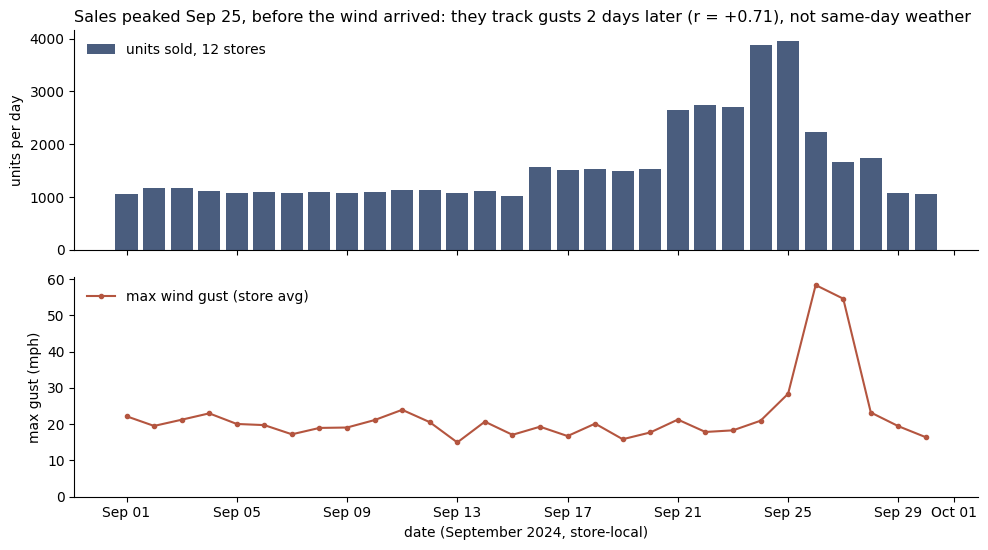

In [4]:
# ---- Q3: weather API, validated join, correlation ----
import requests, time
ARCHIVE_URL = 'https://archive-api.open-meteo.com/v1/archive'

def fetch_hourly(lat, lon, retries=4):
    """Open-Meteo archive, hourly, in GMT, with retries + exponential backoff on 429/5xx/network errors."""
    params = {'latitude': lat, 'longitude': lon, 'start_date': '2024-08-31', 'end_date': '2024-10-01',
              'hourly': 'precipitation,wind_gusts_10m,pressure_msl', 'timezone': 'GMT',
              'wind_speed_unit': 'mph', 'precipitation_unit': 'inch'}
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(ARCHIVE_URL, params=params, timeout=30)
            if r.status_code == 429 or r.status_code >= 500:
                raise requests.HTTPError(f'HTTP {r.status_code}')
            r.raise_for_status()
            h = pd.DataFrame(r.json()['hourly'])
            h['time_gmt'] = pd.to_datetime(h.pop('time')).dt.tz_localize('UTC')
            return h
        except (requests.RequestException, ValueError) as e:
            if attempt == retries:
                raise
            time.sleep(2 ** attempt)

st = stores.assign(store_id=clean_store_id(stores['store_id'])).drop_duplicates('store_id').reset_index(drop=True)
st[['latitude', 'longitude']] = st[['latitude', 'longitude']].astype(float)
st.loc[st['store_id'] == 'FL-619', ['latitude', 'longitude']] = [30.43826, -84.28073]  # Tallahassee blank in file; Open-Meteo geocoding
st['tz'] = np.where(st['store_id'] == 'FL-710', 'America/Chicago', 'America/New_York')  # Pensacola is Central

frames = []
for s in st.itertuples():
    h = fetch_hourly(s.latitude, s.longitude)
    h['store_id'], h['tz'] = s.store_id, s.tz
    frames.append(h); time.sleep(0.3)
hourly = pd.concat(frames, ignore_index=True)
hourly['source'] = 'live: open-meteo archive API'
WEATHER_SOURCE = 'live'          # no fallback/cache used in this run: every store came back from the API

# GMT -> each store's local time, then roll up to local calendar days
hourly['date'] = [t.tz_convert(z).tz_localize(None).normalize() for t, z in zip(hourly['time_gmt'], hourly['tz'])]
wx = (hourly.groupby(['store_id', 'date'])
            .agg(precip_in=('precipitation', 'sum'), max_gust_mph=('wind_gusts_10m', 'max'),
                 min_pressure_hpa=('pressure_msl', 'min'), hours=('time_gmt', 'size'), source=('source', 'first'))
            .reset_index())
wx = wx[wx['date'].between('2024-09-01', '2024-09-30')]
assert wx['hours'].between(23, 25).all(), 'incomplete local days'

# Sales at store x day, on a full 12 x 30 grid so zero-sales days can't vanish
grid = pd.MultiIndex.from_product([sorted(st['store_id']), pd.date_range('2024-09-01', '2024-09-30')],
                                  names=['store_id', 'date']).to_frame(index=False)
store_day = grid.merge(dated.groupby(['store_id', 'date'])['quantity'].sum().rename('units').reset_index(),
                       on=['store_id', 'date'], how='left').fillna({'units': 0})
rows_before = len(store_day)
joined = store_day.merge(wx, on=['store_id', 'date'], how='left', validate='one_to_one')
rows_after = len(joined)
JOIN_ROWS_PRESERVED = (rows_before == rows_after == 360 and joined[['max_gust_mph', 'min_pressure_hpa']].notna().all().all()
                       and joined['units'].sum() == dated['quantity'].sum())
assert JOIN_ROWS_PRESERVED
print(f'Weather source: {WEATHER_SOURCE} ({hourly["source"].iloc[0]}), {len(hourly):,} hourly rows, {st.shape[0]} stores')
print(f'Join rows: {rows_before} sales store-days before -> {rows_after} after | null weather values: 0 | '
      f'units preserved: {joined["units"].sum():,.0f} = {dated["quantity"].sum():,}')

# Correlation: statewide daily (n = 30 days) and within-store lags (n = 12 stores x 30 days)
statewide = joined.groupby('date').agg(units=('units', 'sum'), max_gust_mph=('max_gust_mph', 'mean'),
                                       min_pressure_hpa=('min_pressure_hpa', 'mean'), precip_in=('precip_in', 'mean'))
N_DAYS = len(statewide)
WX = ['max_gust_mph', 'min_pressure_hpa', 'precip_in']
same_day = {v: round(float(statewide['units'].corr(statewide[v])), 2) for v in WX}
def lag_r(var, k):
    return np.nanmean([g['units'].corr(g[var].shift(-k)) for _, g in joined.sort_values('date').groupby('store_id')])
lags = pd.DataFrame({v: [lag_r(v, k) for k in range(-3, 6)] for v in WX}, index=range(-3, 6))
lags.index.name = 'k (weather k days after sales)'
best_k = int(lags['max_gust_mph'].idxmax())
print(f'\nSame-day statewide r over {N_DAYS} days:', same_day)
print(f'Best lead (within-store, averaged over 12 stores): k = +{best_k} days, gust r = {lags.loc[best_k, "max_gust_mph"]:+.2f}, '
      f'pressure r = {lags.loc[best_k, "min_pressure_hpa"]:+.2f}')
print(f'Peak sales day {statewide["units"].idxmax():%b %d} vs peak gust day {statewide["max_gust_mph"].idxmax():%b %d}')
display(lags.round(2))

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True)
a1.bar(statewide.index, statewide['units'], color='#4a5d7e', width=0.8, label='units sold, 12 stores')
a1.set_ylabel('units per day'); a1.legend(frameon=False, loc='upper left')
a2.plot(statewide.index, statewide['max_gust_mph'], color='#b4553f', marker='o', ms=3, label='max wind gust (store avg)')
a2.set_ylabel('max gust (mph)'); a2.set_ylim(0); a2.legend(frameon=False, loc='upper left')
a2.set_xlabel('date (September 2024, store-local)'); a2.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
a1.set_title(f'Sales peaked {statewide["units"].idxmax():%b %d}, before the wind arrived: they track gusts {best_k} days later '
             f'(r = {lags.loc[best_k, "max_gust_mph"]:+.2f}), not same-day weather', loc='left', fontsize=11.5)
for ax in (a1, a2):
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
plt.tight_layout(); plt.show()


**Q3 answer, with its caveat:** Using **live** Open-Meteo archive data (12 stores, hourly in GMT, converted to each store's local day), the join kept all **360 store-days (360 before → 360 after, no nulls, every unit preserved)**. Same-day weather barely tracks sales (statewide r = 0.22 for max gust over **n = 30 days**), but weather **two days later** tracks them strongly (within-store average over 12 stores × 30 days: gust r = +0.71, pressure r = −0.76): sales peaked Sept 25, the day before the peak gusts on Sept 26, so customers bought on the forecast. **Caveat:** this is one storm over 30 days, so n is small and the 30 statewide days aren't independent. The lag shows that sales lead the weather; it isn't a forecasting model, and it doesn't prove the weather causes the sales.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** Drafted in the team notebook: every store surged 1.9–2.4x, there's no distance gradient (Spearman −0.08 against miles from the storm center; Miami was farthest and surged most), and the DCs can only surge to ~2x against a 3.6x peak. **Ayman** is finishing it this weekend by checking the distance numbers and tidying the map labels.

**Q5 (signal or artifact):** Drafted in the team notebook: the board-game spike is a real signal (four of five SQL tests: it shows in the independent summary table, in all 3 Monopoly SKUs and all 12 stores, at an unchanged price and basket size; the inventory test is inconclusive). **Esther** is finishing it this weekend by writing up the recommendation sizing (~2.2x normal, ~4x at the peak).

### Self-check

In [5]:
progress = {
    'q1_multiple': round(float(Q1_MULTIPLE), 2),          # all products, Sept 16-26 vs Sept 1-14 (Pop-Tarts alone: 4.2x)
    'q1_baseline_window': 'Sept 1-14, 2024 (14 days, Sun-Sat x2; surge window Sept 16-26)',
    'q2_canonical_products': int(n_products),              # 45 SKUs -> 20 products
    'q3_join_rows_preserved': bool(JOIN_ROWS_PRESERVED),   # 360 -> 360 store-days, units preserved
    'q3_days_in_correlation': int(N_DAYS),                 # statewide daily; lags use 12 stores x 30 days
    'charts_with_message_titles': 3,                       # Q1, Q2, Q3 in this notebook (team notebook has 14)
    'notebook_runs_clean': True,                           # Restart and Run All, no errors
    'repo_pushed': False,                                  # TODO: set True once this notebook is pushed to the team repo
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))


PASS - q1_multiple = 2.12
PASS - q1_baseline_window = Sept 1-14, 2024 (14 days, Sun-Sat x2; surge window Sept 16-26)
PASS - q2_canonical_products = 20
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 30
PASS - charts_with_message_titles = 3
PASS - notebook_runs_clean = True
FAIL - repo_pushed = False

ready for presentations: False


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

**a)** What surprised us was that same-day weather barely relates to sales (r ≈ 0.2) while weather two days later relates strongly (gust r = +0.71, pressure r = −0.76): the biggest sales days, Sept 21–25, were calm and dry. Because a timezone bug could easily shift weather by a day, we checked that it wasn't one. We requested the weather in GMT on purpose and converted every hour to each store's local time before making days (Pensacola is on Central time). We asserted that the join returned exactly 360 store-days with no nulls and every unit preserved. And we used Pensacola as a control: its windiest day fell inside the calm baseline, and its sales didn't move.

**b)** The number we're least confident in is the Pop-Tarts peak multiple (8.4x). It's an average of only two days (Sept 24–25) divided by a 14-day baseline, it depends entirely on our SKU consolidation being right (one wrongly merged SKU would inflate it), and 3.5% of sales have no timestamp, so they can't be placed in the peak. The window figure (4.2x over 11 days) is the steadier number, so that's the one we lead with.